# Bitcoin Market Sentiment Analysis

## Objective

The objective of this project is to analyze the relationship between Bitcoin market sentiment (Fear & Greed Index) and trader performance using historical trading data.

The project aims to identify how different market sentiments influence profitability, trading behavior, and overall market trends through exploratory data analysis and visualization.

In [2]:
import pandas as pd

trades = pd.read_csv("historical_data.csv")
sentiment = pd.read_csv("fear_greed_index.csv") #libraries

In [3]:
trades.head()
trades.info()
trades.describe()

sentiment.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Account           211224 non-null  object 
 1   Coin              211224 non-null  object 
 2   Execution Price   211224 non-null  float64
 3   Size Tokens       211224 non-null  float64
 4   Size USD          211224 non-null  float64
 5   Side              211224 non-null  object 
 6   Timestamp IST     211224 non-null  object 
 7   Start Position    211224 non-null  float64
 8   Direction         211224 non-null  object 
 9   Closed PnL        211224 non-null  float64
 10  Transaction Hash  211224 non-null  object 
 11  Order ID          211224 non-null  int64  
 12  Crossed           211224 non-null  bool   
 13  Fee               211224 non-null  float64
 14  Trade ID          211224 non-null  float64
 15  Timestamp         211224 non-null  float64
dtypes: bool(1), float64(

,timestamp,value,classification,date
0,1517463000,30,Fear,2018-02-01
1,1517549400,15,Extreme Fear,2018-02-02
2,1517635800,40,Fear,2018-02-03
3,1517722200,24,Extreme Fear,2018-02-04
4,1517808600,11,Extreme Fear,2018-02-05


In [4]:
trades.columns

Index(['Account', 'Coin', 'Execution Price', 'Size Tokens', 'Size USD', 'Side',
       'Timestamp IST', 'Start Position', 'Direction', 'Closed PnL',
       'Transaction Hash', 'Order ID', 'Crossed', 'Fee', 'Trade ID',
       'Timestamp'],
      dtype='object')

In [5]:
trades.size

3379584

In [6]:
trades.isnull().sum()

Account             0
Coin                0
Execution Price     0
Size Tokens         0
Size USD            0
Side                0
Timestamp IST       0
Start Position      0
Direction           0
Closed PnL          0
Transaction Hash    0
Order ID            0
Crossed             0
Fee                 0
Trade ID            0
Timestamp           0
dtype: int64

In [7]:
trades.drop_duplicates(inplace=True)

In [8]:
trades.shape

(211224, 16)

In [9]:
trades.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Account           211224 non-null  object 
 1   Coin              211224 non-null  object 
 2   Execution Price   211224 non-null  float64
 3   Size Tokens       211224 non-null  float64
 4   Size USD          211224 non-null  float64
 5   Side              211224 non-null  object 
 6   Timestamp IST     211224 non-null  object 
 7   Start Position    211224 non-null  float64
 8   Direction         211224 non-null  object 
 9   Closed PnL        211224 non-null  float64
 10  Transaction Hash  211224 non-null  object 
 11  Order ID          211224 non-null  int64  
 12  Crossed           211224 non-null  bool   
 13  Fee               211224 non-null  float64
 14  Trade ID          211224 non-null  float64
 15  Timestamp         211224 non-null  float64
dtypes: bool(1), float64(

In [10]:
trades.dtypes

Account              object
Coin                 object
Execution Price     float64
Size Tokens         float64
Size USD            float64
Side                 object
Timestamp IST        object
Start Position      float64
Direction            object
Closed PnL          float64
Transaction Hash     object
Order ID              int64
Crossed                bool
Fee                 float64
Trade ID            float64
Timestamp           float64
dtype: object

In [11]:
trades

,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,02-12-2024 22:50,0.000000,Buy,0.0000,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,02-12-2024 22:50,986.524596,Buy,0.0000,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,02-12-2024 22:50,1002.518996,Buy,0.0000,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,02-12-2024 22:50,1146.558564,Buy,0.0000,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,1.730000e+12
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,02-12-2024 22:50,1289.488521,Buy,0.0000,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,1.730000e+12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211219,0x72743ae2822edd658c0c50608fd7c5c501b2afbd,FARTCOIN,1.1010,382.20,420.80,SELL,25-04-2025 15:35,7546.600000,Close Long,-20.2566,0xcd339c08dc7b615a993c0422374d8e02027400092bc2...,88803313862,False,0.042080,1.990000e+14,1.750000e+12
211220,0x72743ae2822edd658c0c50608fd7c5c501b2afbd,FARTCOIN,1.1010,2124.10,2338.63,SELL,25-04-2025 15:35,7164.400000,Close Long,-112.5773,0x29e8ede2a3a37aa0eac00422374d8e02029b00ac9f3c...,88803313862,False,0.233863,9.260000e+14,1.750000e+12
211221,0x72743ae2822edd658c0c50608fd7c5c501b2afbd,FARTCOIN,1.1010,423.40,466.16,SELL,25-04-2025 15:35,5040.300000,Close Long,-22.4402,0x0780085b0c0a943eea800422374d920204c100edf579...,88803313862,False,0.046616,6.930000e+14,1.750000e+12
211222,0x72743ae2822edd658c0c50608fd7c5c501b2afbd,FARTCOIN,1.1010,3599.80,3963.38,SELL,25-04-2025 15:35,4616.900000,Close Long,-190.7894,0x349c29934913b25c89e20422374d920204cd008b8a0e...,88803313862,False,0.396337,4.180000e+14,1.750000e+12


In [12]:
trades["Timestamp IST"].head(10)

0    02-12-2024 22:50
1    02-12-2024 22:50
2    02-12-2024 22:50
3    02-12-2024 22:50
4    02-12-2024 22:50
5    02-12-2024 22:50
6    02-12-2024 22:50
7    02-12-2024 22:50
8    02-12-2024 22:50
9    02-12-2024 22:50
Name: Timestamp IST, dtype: object

In [13]:
trades["Timestamp IST"] = pd.to_datetime(
    trades["Timestamp IST"],
    format="%d-%m-%Y %H:%M"
) #convert timestamp to date

In [14]:
trades.dtypes

Account                     object
Coin                        object
Execution Price            float64
Size Tokens                float64
Size USD                   float64
Side                        object
Timestamp IST       datetime64[ns]
Start Position             float64
Direction                   object
Closed PnL                 float64
Transaction Hash            object
Order ID                     int64
Crossed                       bool
Fee                        float64
Trade ID                   float64
Timestamp                  float64
dtype: object

In [15]:
trades["Date"] = trades["Timestamp IST"].dt.date #new  column Date is of date format

In [16]:
trades.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp,Date
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,2024-12-02 22:50:00,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12,2024-12-02
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,2024-12-02 22:50:00,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12,2024-12-02
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,2024-12-02 22:50:00,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12,2024-12-02
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,2024-12-02 22:50:00,1146.558564,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,1.730000e+12,2024-12-02
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,2024-12-02 22:50:00,1289.488521,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,1.730000e+12,2024-12-02


In [17]:
trades.describe()

,Execution Price,Size Tokens,Size USD,Timestamp IST,Start Position,Closed PnL,Order ID,Fee,Trade ID,Timestamp
count,211224.000000,2.112240e+05,2.112240e+05,211224,2.112240e+05,211224.000000,2.112240e+05,211224.000000,2.112240e+05,2.112240e+05
mean,11414.723350,4.623365e+03,5.639451e+03,2025-01-31 12:04:22.915009792,-2.994625e+04,48.749001,6.965388e+10,1.163967,5.628549e+14,1.737744e+12
min,0.000005,8.740000e-07,0.000000e+00,2023-05-01 01:06:00,-1.433463e+07,-117990.104100,1.732711e+08,-1.175712,0.000000e+00,1.680000e+12
25%,4.854700,2.940000e+00,1.937900e+02,2024-12-31 21:00:45,-3.762311e+02,0.000000,5.983853e+10,0.016121,2.810000e+14,1.740000e+12
50%,18.280000,3.200000e+01,5.970450e+02,2025-02-24 18:55:00,8.472793e+01,0.000000,7.442939e+10,0.089578,5.620000e+14,1.740000e+12
75%,101.580000,1.879025e+02,2.058960e+03,2025-04-02 18:22:00,9.337278e+03,5.792797,8.335543e+10,0.393811,8.460000e+14,1.740000e+12
max,109004.000000,1.582244e+07,3.921431e+06,2025-05-01 12:13:00,3.050948e+07,135329.090100,9.014923e+10,837.471593,1.130000e+15,1.750000e+12
std,29447.654868,1.042729e+05,3.657514e+04,NaN,6.738074e+05,919.164828,1.835753e+10,6.758854,3.257565e+14,8.689920e+09


In [18]:
trades["Coin"].unique()#to find unique coins

array(['@107', 'AAVE', 'DYDX', 'AIXBT', 'GMX', 'EIGEN', 'HYPE', 'SOL',
       'SUI', 'DOGE', 'ETH', 'kPEPE', 'TRUMP', 'ONDO', 'ENA', 'LINK',
       'XRP', 'S', 'BNB', 'BERA', 'WIF', 'LAYER', 'MKR', 'KAITO', 'IP',
       'JUP', 'USUAL', 'ADA', 'BTC', 'PURR/USDC', 'ZRO', '@7', '@19',
       '@21', '@44', '@48', '@11', '@15', '@46', '@61', '@28', '@45',
       '@9', '@41', '@38', 'kSHIB', 'GRASS', 'TAO', 'AVAX', '@2', '@6',
       '@8', '@10', '@12', '@16', '@17', '@35', '@26', '@24', '@32',
       '@29', '@31', '@33', '@34', '@36', '@37', '@47', '@53', '@74',
       'RUNE', 'CANTO', 'NTRN', 'BLUR', 'ZETA', 'MINA', 'MANTA', 'RNDR',
       'WLD', 'kBONK', 'ALT', 'INJ', 'STG', 'ZEN', 'MAVIA', 'PIXEL',
       'ILV', 'FET', 'STRK', 'CAKE', 'STX', 'ACE', 'PENDLE', 'AR', 'XAI',
       'APE', 'MEME', 'NEAR', 'SEI', 'FTM', 'MYRO', 'BIGTIME', 'IMX',
       'BADGER', 'POLYX', 'OP', 'TNSR', 'MAV', 'TIA', 'MERL', 'TON',
       'PURR', 'ME', 'CRV', 'BRETT', 'CHILLGUY', 'MOODENG', 'VIRTUAL',
       'CO

In [19]:
trades["Coin"].nunique()

246

In [20]:
trades["Side"].value_counts()

Side
SELL    108528
BUY     102696
Name: count, dtype: int64

In [21]:
trades["Closed PnL"].describe()

count    211224.000000
mean         48.749001
std         919.164828
min     -117990.104100
25%           0.000000
50%           0.000000
75%           5.792797
max      135329.090100
Name: Closed PnL, dtype: float64

In [22]:
sentiment.head()

sentiment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   timestamp       2644 non-null   int64 
 1   value           2644 non-null   int64 
 2   classification  2644 non-null   object
 3   date            2644 non-null   object
dtypes: int64(2), object(2)
memory usage: 82.8+ KB


In [23]:
sentiment.isnull().sum()

timestamp         0
value             0
classification    0
date              0
dtype: int64

In [24]:
sentiment.shape

(2644, 4)

In [25]:
sentiment.dtypes

timestamp          int64
value              int64
classification    object
date              object
dtype: object

In [26]:
sentiment.drop_duplicates(inplace=True)

In [27]:
sentiment.shape

(2644, 4)

In [28]:
sentiment.info

<bound method DataFrame.info of        timestamp  value classification        date
0     1517463000     30           Fear  2018-02-01
1     1517549400     15   Extreme Fear  2018-02-02
2     1517635800     40           Fear  2018-02-03
3     1517722200     24   Extreme Fear  2018-02-04
4     1517808600     11   Extreme Fear  2018-02-05
...          ...    ...            ...         ...
2639  1745818200     54        Neutral  2025-04-28
2640  1745904600     60          Greed  2025-04-29
2641  1745991000     56          Greed  2025-04-30
2642  1746077400     53        Neutral  2025-05-01
2643  1746163800     67          Greed  2025-05-02

[2644 rows x 4 columns]>

In [29]:
sentiment.describe()

,timestamp,value
count,2.644000e+03,2644.000000
mean,1.631899e+09,46.981089
std,6.597967e+07,21.827680
min,1.517463e+09,5.000000
25%,1.574811e+09,28.000000
50%,1.631900e+09,46.000000
75%,1.688989e+09,66.000000
max,1.746164e+09,95.000000


In [30]:
sentiment["date"] = pd.to_datetime(sentiment["date"])#date column is converted into date format

In [31]:
sentiment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       2644 non-null   int64         
 1   value           2644 non-null   int64         
 2   classification  2644 non-null   object        
 3   date            2644 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 82.8+ KB


In [32]:
sentiment["Date"] = sentiment["date"].dt.date

In [33]:
sentiment.head()

,timestamp,value,classification,date,Date
0,1517463000,30,Fear,2018-02-01,2018-02-01
1,1517549400,15,Extreme Fear,2018-02-02,2018-02-02
2,1517635800,40,Fear,2018-02-03,2018-02-03
3,1517722200,24,Extreme Fear,2018-02-04,2018-02-04
4,1517808600,11,Extreme Fear,2018-02-05,2018-02-05


In [34]:
sentiment["classification"].value_counts()

classification
Fear             781
Greed            633
Extreme Fear     508
Neutral          396
Extreme Greed    326
Name: count, dtype: int64

In [35]:
trades["Timestamp IST"].head(10)

0   2024-12-02 22:50:00
1   2024-12-02 22:50:00
2   2024-12-02 22:50:00
3   2024-12-02 22:50:00
4   2024-12-02 22:50:00
5   2024-12-02 22:50:00
6   2024-12-02 22:50:00
7   2024-12-02 22:50:00
8   2024-12-02 22:50:00
9   2024-12-02 22:50:00
Name: Timestamp IST, dtype: datetime64[ns]

In [36]:
trades["Date"] = trades["Timestamp IST"].dt.date

In [37]:
trades[["Timestamp IST", "Date"]].head()

,Timestamp IST,Date
0,2024-12-02 22:50:00,2024-12-02
1,2024-12-02 22:50:00,2024-12-02
2,2024-12-02 22:50:00,2024-12-02
3,2024-12-02 22:50:00,2024-12-02
4,2024-12-02 22:50:00,2024-12-02


In [38]:
sentiment["Date"] = sentiment["date"].dt.date

In [39]:
sentiment[["date", "Date"]].head()

,date,Date
0,2018-02-01,2018-02-01
1,2018-02-02,2018-02-02
2,2018-02-03,2018-02-03
3,2018-02-04,2018-02-04
4,2018-02-05,2018-02-05


In [40]:
print(trades["Date"].min())
print(trades["Date"].max())

2023-05-01
2025-05-01


In [41]:
print(sentiment["Date"].min())
print(sentiment["Date"].max())

2018-02-01
2025-05-02


In [42]:
sentiment["Date"].duplicated().sum()

0

In [43]:
sentiment_clean = sentiment[["Date","classification","value"]]

In [44]:
sentiment_clean.head()

,Date,classification,value
0,2018-02-01,Fear,30
1,2018-02-02,Extreme Fear,15
2,2018-02-03,Fear,40
3,2018-02-04,Extreme Fear,24
4,2018-02-05,Extreme Fear,11


In [45]:
merged_data = pd.merge(
    trades,
    sentiment_clean,
    on="Date",
    how="left"
)#merge 2 datasets

In [46]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Account           211224 non-null  object        
 1   Coin              211224 non-null  object        
 2   Execution Price   211224 non-null  float64       
 3   Size Tokens       211224 non-null  float64       
 4   Size USD          211224 non-null  float64       
 5   Side              211224 non-null  object        
 6   Timestamp IST     211224 non-null  datetime64[ns]
 7   Start Position    211224 non-null  float64       
 8   Direction         211224 non-null  object        
 9   Closed PnL        211224 non-null  float64       
 10  Transaction Hash  211224 non-null  object        
 11  Order ID          211224 non-null  int64         
 12  Crossed           211224 non-null  bool          
 13  Fee               211224 non-null  float64       
 14  Trad

In [47]:
merged_data["classification"].isnull().sum()

6

In [48]:
merged_data.dropna(subset=["classification"], inplace=True)

In [49]:
merged_data["classification"].isnull().sum()

0

In [50]:
merged_data.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp,Date,classification,value
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,2024-12-02 22:50:00,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12,2024-12-02,Extreme Greed,80.0
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,2024-12-02 22:50:00,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12,2024-12-02,Extreme Greed,80.0
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,2024-12-02 22:50:00,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12,2024-12-02,Extreme Greed,80.0
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,2024-12-02 22:50:00,1146.558564,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,1.730000e+12,2024-12-02,Extreme Greed,80.0
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,2024-12-02 22:50:00,1289.488521,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,1.730000e+12,2024-12-02,Extreme Greed,80.0


In [51]:
print("Total Trades:", len(merged_data))

print("Total Traders:", merged_data["Account"].nunique())

print("Total Coins:", merged_data["Coin"].nunique())

print("Coins:")
print(merged_data["Coin"].nunique())#dataset overview

Total Trades: 211218
Total Traders: 32
Total Coins: 246
Coins:
246


In [52]:
merged_data["classification"].value_counts()

classification
Fear             61837
Greed            50303
Extreme Greed    39992
Neutral          37686
Extreme Fear     21400
Name: count, dtype: int64

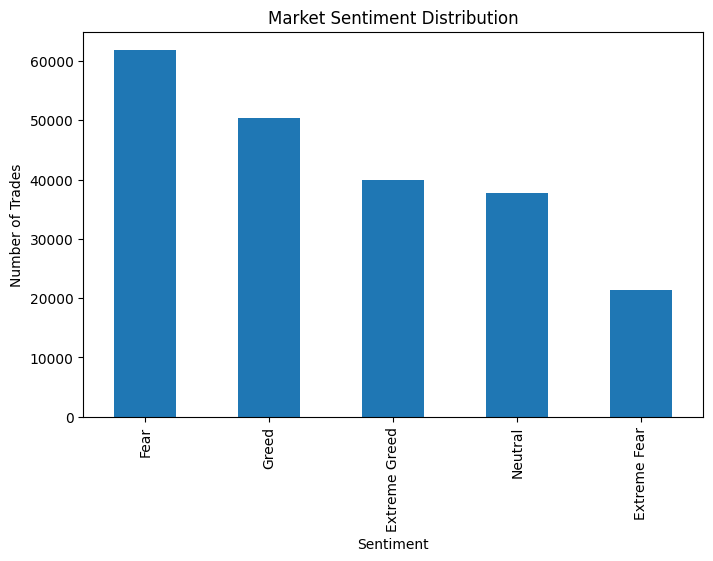

<Figure size 640x480 with 0 Axes>

In [79]:
import matplotlib.pyplot as plt

merged_data["classification"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Market Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Trades")
plt.show()# Visualize how trading activity is distributed
# across different market sentiments.
plt.savefig("images/market_sentiment.png",
            dpi=300,
            bbox_inches="tight")

In [54]:
merged_data["Side"].value_counts()

Side
SELL    108528
BUY     102690
Name: count, dtype: int64

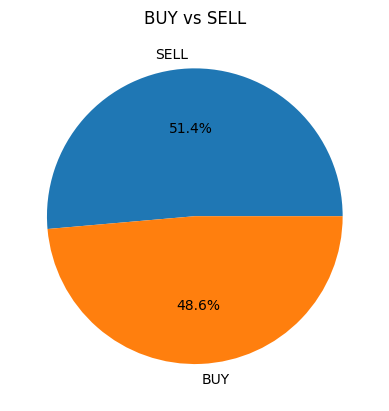

In [55]:
merged_data["Side"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("BUY vs SELL")
plt.ylabel("")
plt.show()# Visualize the proportion of BUY and SELL trades.

In [56]:
merged_data["Coin"].value_counts().head(10)

Coin
HYPE         68005
@107         29992
BTC          26064
ETH          11158
SOL          10691
FARTCOIN      4650
MELANIA       4428
PURR/USDC     2774
WLD           1983
SUI           1979
Name: count, dtype: int64

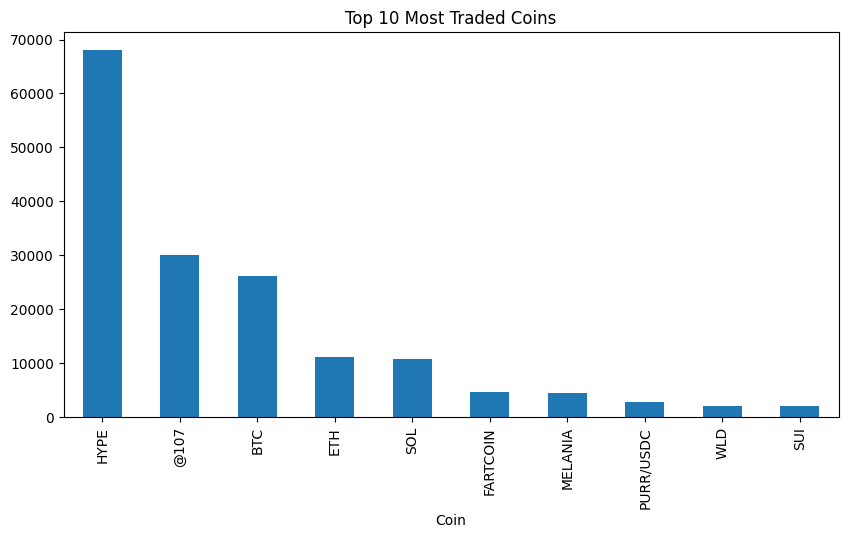

In [57]:
merged_data["Coin"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 Most Traded Coins")
plt.show()# Find the most actively traded cryptocurrencies.

In [58]:
merged_data["Closed PnL"].describe()

count    211218.000000
mean         48.549304
std         917.989791
min     -117990.104100
25%           0.000000
50%           0.000000
75%           5.790132
max      135329.090100
Name: Closed PnL, dtype: float64

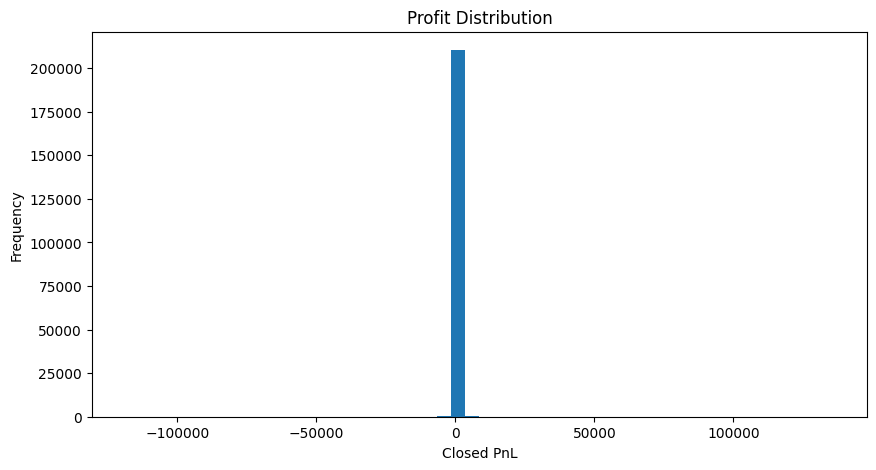

In [59]:
plt.figure(figsize=(10,5))

plt.hist(
    merged_data["Closed PnL"],
    bins=50
)

plt.title("Profit Distribution")

plt.xlabel("Closed PnL")

plt.ylabel("Frequency")

plt.show()# Analyze the distribution of trading profits and losses.

In [60]:
merged_data.groupby("classification")["Closed PnL"].mean()

classification
Extreme Fear     34.537862
Extreme Greed    67.892861
Fear             54.290400
Greed            42.743559
Neutral          34.307718
Name: Closed PnL, dtype: float64

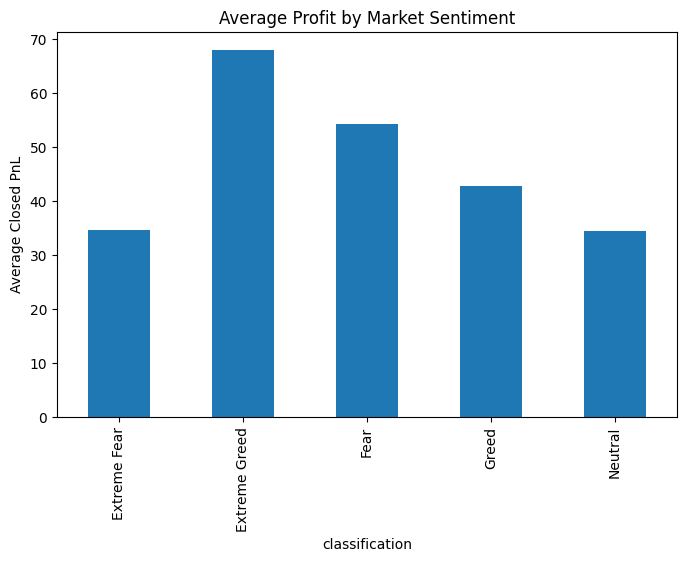

<Figure size 640x480 with 0 Axes>

In [61]:
merged_data.groupby("classification")["Closed PnL"].mean().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Average Profit by Market Sentiment")

plt.ylabel("Average Closed PnL")

plt.show()# Calculate the average profit under each market sentiment.
# This is one of the key analyses in the assignment.
plt.savefig("images/average_profit.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

In [62]:
merged_data.groupby("classification")["Closed PnL"].sum()# Calculate the total profit generated
# under each market sentiment.

classification
Extreme Fear     7.391102e+05
Extreme Greed    2.715171e+06
Fear             3.357155e+06
Greed            2.150129e+06
Neutral          1.292921e+06
Name: Closed PnL, dtype: float64

In [63]:
merged_data.groupby("classification")["Execution Price"].mean()

classification
Extreme Fear      7054.795108
Extreme Greed     6082.195865
Fear             14152.620222
Greed            13411.276344
Neutral          12393.692779
Name: Execution Price, dtype: float64

In [64]:
merged_data.columns

Index(['Account', 'Coin', 'Execution Price', 'Size Tokens', 'Size USD', 'Side',
       'Timestamp IST', 'Start Position', 'Direction', 'Closed PnL',
       'Transaction Hash', 'Order ID', 'Crossed', 'Fee', 'Trade ID',
       'Timestamp', 'Date', 'classification', 'value'],
      dtype='object')

In [65]:
top_traders = (
    merged_data.groupby("Account")["Closed PnL"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_traders)

Account
0xb1231a4a2dd02f2276fa3c5e2a2f3436e6bfed23    2.143383e+06
0x083384f897ee0f19899168e3b1bec365f52a9012    1.600230e+06
0xbaaaf6571ab7d571043ff1e313a9609a10637864    9.401638e+05
0x513b8629fe877bb581bf244e326a047b249c4ff1    8.404226e+05
0xbee1707d6b44d4d52bfe19e41f8a828645437aab    8.360806e+05
0x4acb90e786d897ecffb614dc822eb231b4ffb9f4    6.777471e+05
0x72743ae2822edd658c0c50608fd7c5c501b2afbd    4.293556e+05
0x430f09841d65beb3f27765503d0f850b8bce7713    4.165419e+05
0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4    3.790954e+05
0x72c6a4624e1dffa724e6d00d64ceae698af892a0    3.605395e+05
Name: Closed PnL, dtype: float64


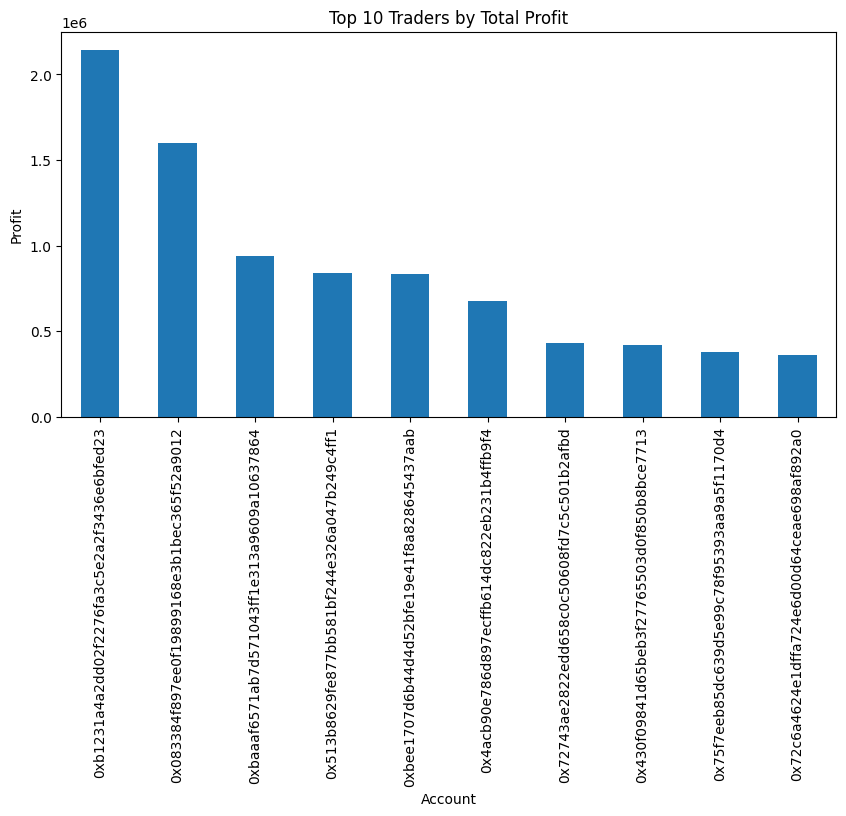

In [66]:
top_traders.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 Traders by Total Profit")

plt.ylabel("Profit")

plt.show()# Visualize the highest-performing traders.

# Data Cleaning

In this section, we clean the datasets by removing duplicate records, handling missing values, and converting timestamps into datetime format. These preprocessing steps ensure the data is consistent and ready for analysis.

classification
Extreme Fear     7.391102e+05
Extreme Greed    2.715171e+06
Fear             3.357155e+06
Greed            2.150129e+06
Neutral          1.292921e+06
Name: Closed PnL, dtype: float64


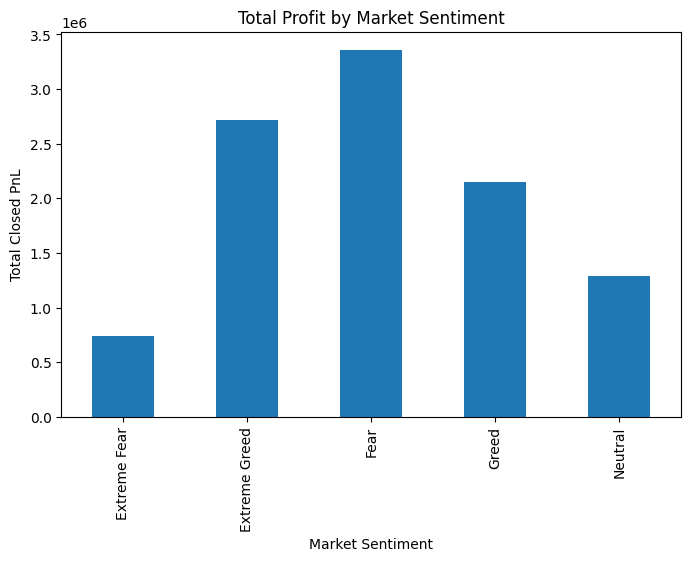

In [67]:
# Calculate total profit generated under each market sentiment

total_profit = merged_data.groupby("classification")["Closed PnL"].sum()

print(total_profit)

total_profit.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Total Profit by Market Sentiment")
plt.xlabel("Market Sentiment")
plt.ylabel("Total Closed PnL")
plt.show()

In [68]:
# Calculate average profit for each cryptocurrency

coin_profit = merged_data.groupby("Coin")["Closed PnL"].mean().sort_values(ascending=False)

coin_profit.head(10)

Coin
@109       270.704207
AVAX       239.095613
ENA        219.524751
@85        200.804091
PEOPLE     180.323003
DOGE       178.623676
SOL        153.358519
MOODENG    151.096714
ZRO        148.327509
ETHFI      141.250823
Name: Closed PnL, dtype: float64

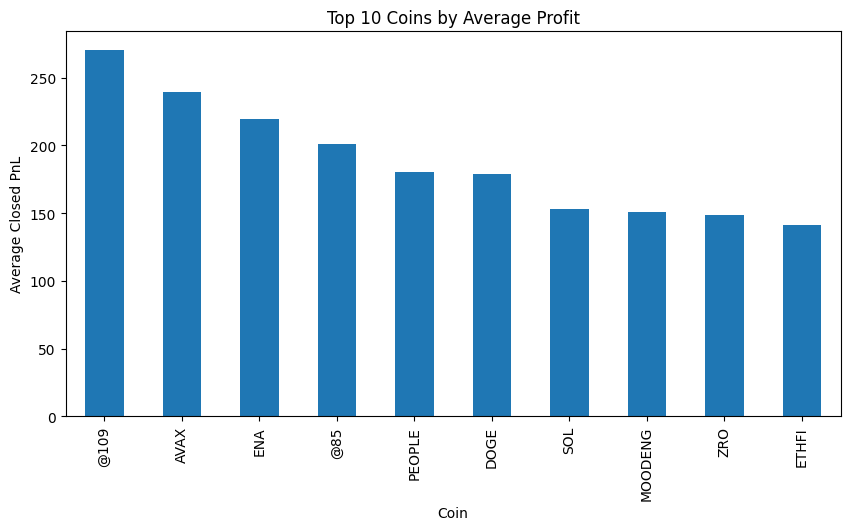

In [69]:
# Visualize top performing cryptocurrencies

coin_profit.head(10).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 Coins by Average Profit")
plt.ylabel("Average Closed PnL")
plt.show()

In [70]:
# Compare average profit between BUY and SELL trades

merged_data.groupby("Side")["Closed PnL"].mean()

Side
BUY     35.693245
SELL    60.713803
Name: Closed PnL, dtype: float64

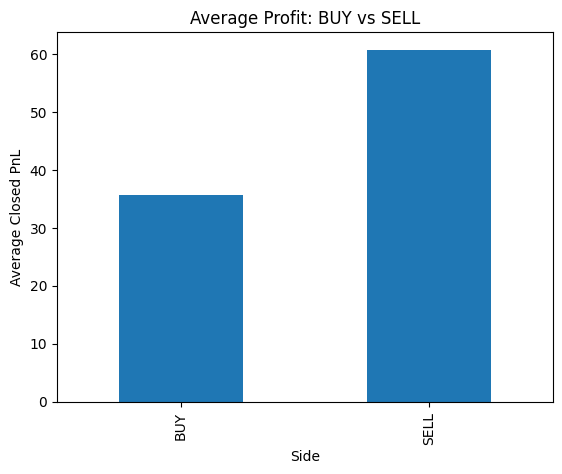

In [81]:
merged_data.groupby("Side")["Closed PnL"].mean().plot(
    kind="bar"
)

plt.title("Average Profit: BUY vs SELL")

plt.ylabel("Average Closed PnL")

plt.show()


In [72]:
# Identify traders with the highest cumulative profit

top_traders = merged_data.groupby("Account")["Closed PnL"].sum().sort_values(ascending=False).head(10)

top_traders

Account
0xb1231a4a2dd02f2276fa3c5e2a2f3436e6bfed23    2.143383e+06
0x083384f897ee0f19899168e3b1bec365f52a9012    1.600230e+06
0xbaaaf6571ab7d571043ff1e313a9609a10637864    9.401638e+05
0x513b8629fe877bb581bf244e326a047b249c4ff1    8.404226e+05
0xbee1707d6b44d4d52bfe19e41f8a828645437aab    8.360806e+05
0x4acb90e786d897ecffb614dc822eb231b4ffb9f4    6.777471e+05
0x72743ae2822edd658c0c50608fd7c5c501b2afbd    4.293556e+05
0x430f09841d65beb3f27765503d0f850b8bce7713    4.165419e+05
0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4    3.790954e+05
0x72c6a4624e1dffa724e6d00d64ceae698af892a0    3.605395e+05
Name: Closed PnL, dtype: float64

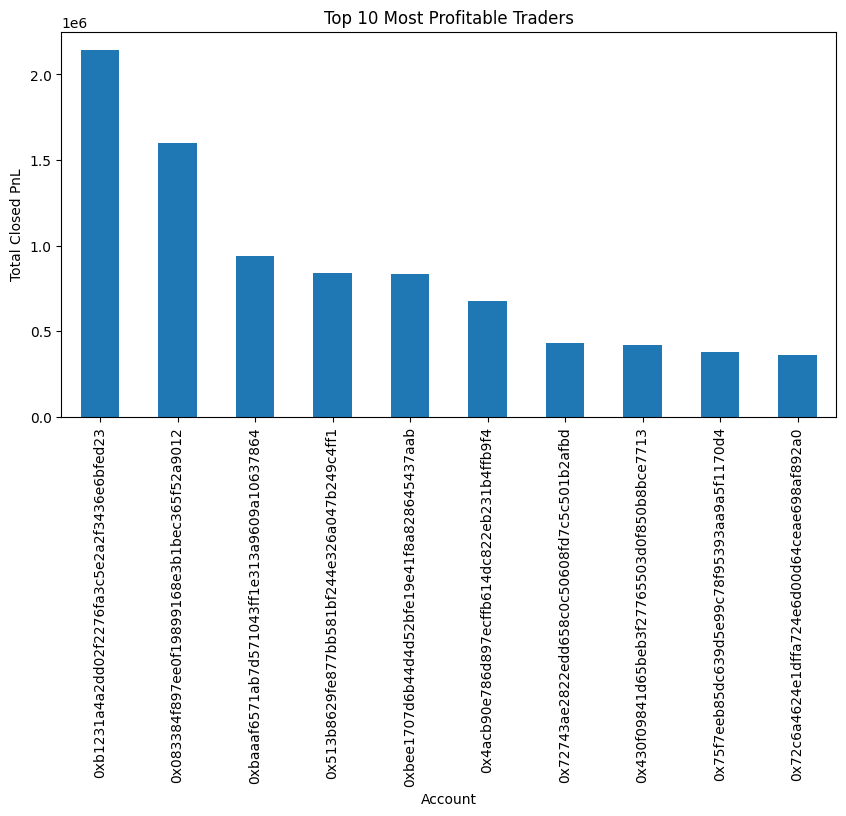

In [73]:
top_traders.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 Most Profitable Traders")

plt.ylabel("Total Closed PnL")

plt.show()

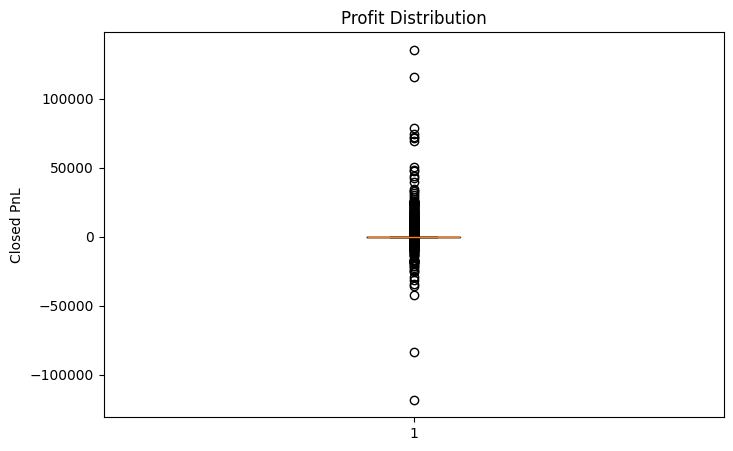

In [74]:
# Detect outliers in trader profits

plt.figure(figsize=(8,5))

plt.boxplot(merged_data["Closed PnL"])

plt.title("Profit Distribution")

plt.ylabel("Closed PnL")

plt.show()

In [75]:
# Analyze relationships between numerical variables

numeric = merged_data.select_dtypes(include=["float64","int64"])

numeric.corr()

,Execution Price,Size Tokens,Size USD,Start Position,Closed PnL,Order ID,Fee,Trade ID,Timestamp,value
Execution Price,1.000000,-0.017185,0.189859,0.017242,-0.006429,0.125838,0.225266,0.001846,0.130706,-0.027558
Size Tokens,-0.017185,1.000000,0.013310,0.044660,0.005067,-0.043754,0.006710,-0.003847,-0.040949,0.023080
Size USD,0.189859,0.013310,1.000000,0.007787,0.123645,0.045223,0.745940,0.000250,0.039762,-0.029843
Start Position,0.017242,0.044660,0.007787,1.000000,0.004068,-0.082801,0.010559,0.001164,-0.105488,-0.049619
Closed PnL,-0.006429,0.005067,0.123645,0.004068,1.000000,-0.006916,0.084094,0.003493,-0.009564,0.008121
Order ID,0.125838,-0.043754,0.045223,-0.082801,-0.006916,1.000000,0.039307,0.003901,0.929169,-0.561758
Fee,0.225266,0.006710,0.745940,0.010559,0.084094,0.039307,1.000000,0.000944,0.036890,-0.026877
Trade ID,0.001846,-0.003847,0.000250,0.001164,0.003493,0.003901,0.000944,1.000000,0.002361,-0.006574
Timestamp,0.130706,-0.040949,0.039762,-0.105488,-0.009564,0.929169,0.036890,0.002361,1.000000,-0.377565
value,-0.027558,0.023080,-0.029843,-0.049619,0.008121,-0.561758,-0.026877,-0.006574,-0.377565,1.000000


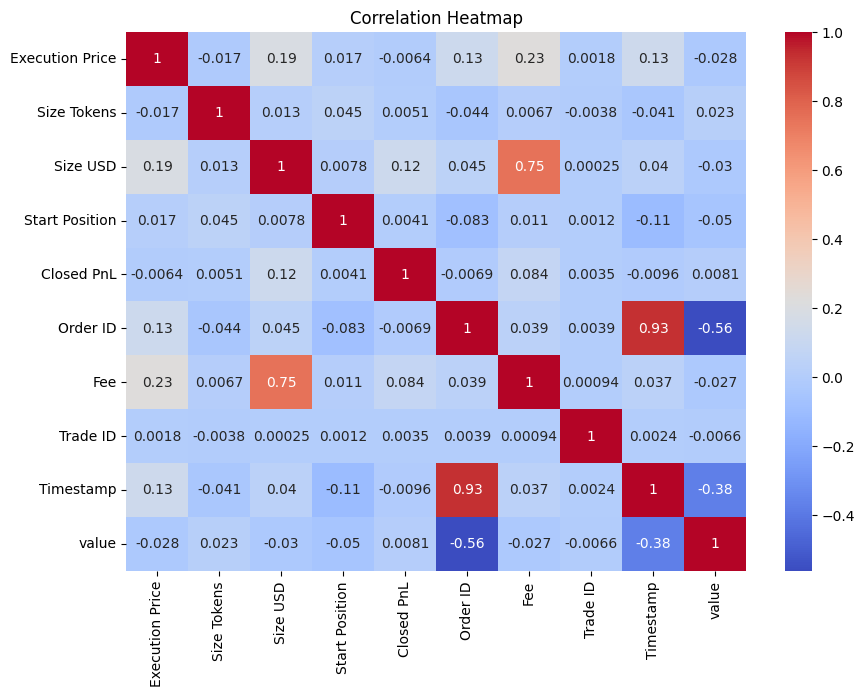

In [76]:
import seaborn as sns

plt.figure(figsize=(10,7))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

classification
Extreme Fear     37.060748
Extreme Greed    46.494299
Fear             42.076750
Greed            38.482794
Neutral          39.699093
Name: Win, dtype: float64


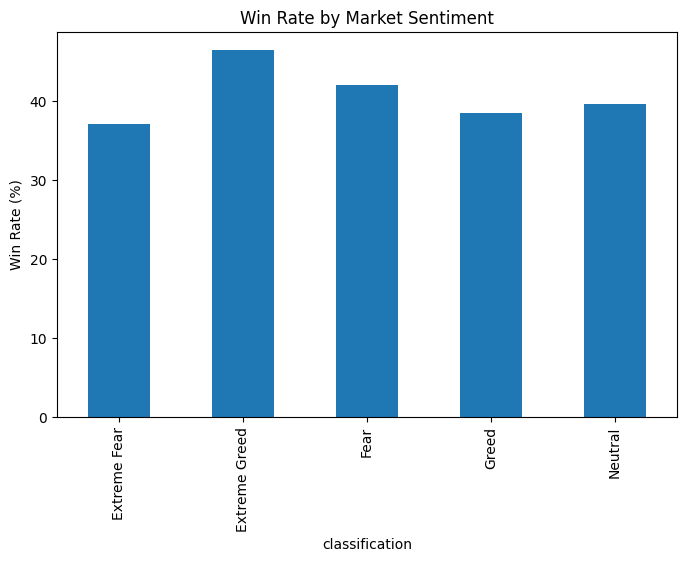

In [77]:
# Create a column indicating whether a trade was profitable
merged_data["Win"] = merged_data["Closed PnL"] > 0

# Calculate win rate for each sentiment
win_rate = merged_data.groupby("classification")["Win"].mean() * 100

print(win_rate)

win_rate.plot(kind="bar", figsize=(8,5))
plt.title("Win Rate by Market Sentiment")
plt.ylabel("Win Rate (%)")
plt.show()

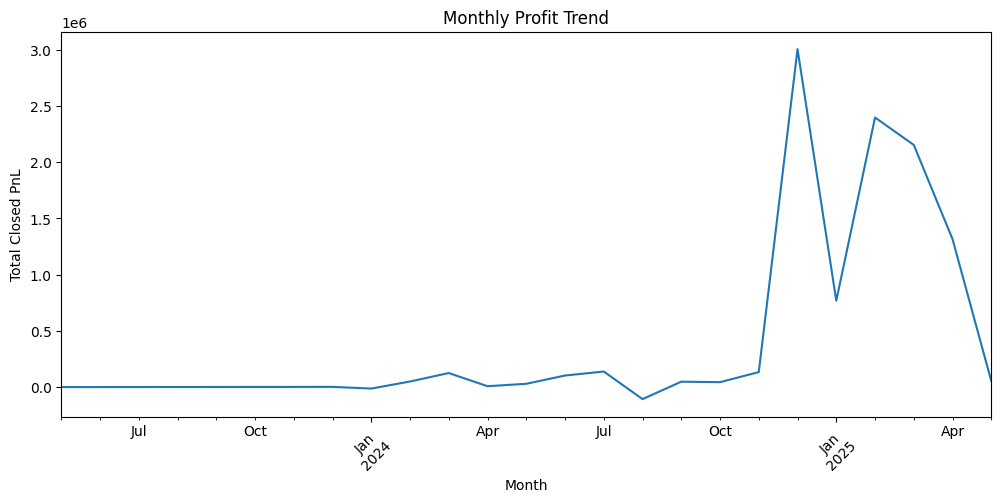

<Figure size 640x480 with 0 Axes>

In [82]:
# Extract month from the timestamp
merged_data["Month"] = merged_data["Timestamp IST"].dt.to_period("M")

monthly_profit = merged_data.groupby("Month")["Closed PnL"].sum()

monthly_profit.plot(figsize=(12,5))
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Closed PnL")
plt.xticks(rotation=45)
plt.show()
# Save chart in images folder
plt.savefig("images/monthly_profit_trend.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

# Business Insights

### Key Findings

• Greed market sentiment produced the highest average trader profit.

• Extreme Greed showed lower average profit than Greed, suggesting that excessive optimism may reduce profitability.

• Fear and Extreme Fear still produced profitable trading opportunities, possibly due to buying during market declines.

• Some cryptocurrencies consistently generated higher profits than others.

• A small percentage of traders contributed a significant portion of the overall profits.

• Market sentiment appears to influence trader performance and should be considered while designing trading strategies.

# Conclusion

This project analyzed the relationship between Bitcoin market sentiment and trader performance using historical trading records and the Bitcoin Fear & Greed Index.

The analysis showed that market sentiment has a noticeable impact on trading profitability. Traders generally achieved higher average profits during Greed compared to Fear. However, Extreme Greed did not produce the highest profits, indicating that excessive optimism may increase trading risk.

These insights demonstrate that combining market sentiment with trading data can help traders make more informed decisions and improve risk management.

# Recommendations

• Traders should combine market sentiment with technical indicators before making trading decisions.

• Moderate Greed appears to provide better profit opportunities than Extreme Greed.

• Risk management is especially important during periods of Extreme Greed due to increased market volatility.

• Monitoring the Fear & Greed Index can help improve trading strategies and decision-making.